# Understat — shots, source coverage and attacking profiles

Raw CSVs are source-preserving exports from the five pinned GitHub shot archives. Understat remains separate from FBref; source IDs are not universal player IDs.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = Path.cwd()
while not (ROOT/'src/config.py').exists():
    if ROOT == ROOT.parent: raise RuntimeError('Run within the project')
    ROOT = ROOT.parent
import sys
sys.path.insert(0,str(ROOT))
from src.data.provenance import sha256
manifest=json.loads((ROOT/'data/processed/manifest.json').read_text(encoding='utf-8'))
def table(name):
    info=manifest['outputs'][name]
    path=ROOT/info['parquet_path']
    assert sha256(path)==info['parquet_sha256'], 'Prepared table checksum changed'
    return pd.read_parquet(path)


In [2]:
shots=table('understat_shots');players=table('understat_player_seasons');quarantine=table('understat_quarantine')
print('Observed shots:',len(shots),'Player-season summaries:',len(players),'Quarantined:',len(quarantine))
print('Duplicate league/shot keys:',int(shots.duplicated(['league','shot_id']).sum()))
shots.groupby(['league','season']).agg(shots=('shot_id','size'),players=('source_player_id','nunique'),matches=('match_id','nunique'))

Observed shots: 228785 Player-season summaries: 12809 Quarantined: 0
Duplicate league/shot keys: 0


shots  players  matches
league         season                            
Bundesliga     2020-2021   7590      417      306
               2021-2022   7949      414      306
               2022-2023   7815      411      306
               2023-2024   8506      411      306
               2024-2025   7945      409      305
               2025-2026    713      232       27
La Liga        2020-2021   8132      473      380
               2021-2022   8977      500      380
               2022-2023   9374      480      380
               2023-2024   9311      490      380
               2024-2025   9056      488      380
               2025-2026    997      291       41
Ligue 1        2020-2021   8921      471      380
               2021-2022   9132      476      380
               2022-2023   9345      482      380
               2023-2024   7827      444      306
               2024-2025   7647      437      306
               2025-2026    905      259       36
Premier League 2020-2021   9235      437      380
               2021-2022   9775      450      380
               2022-2023   9644      461      380
               2023-2024  10524      467      380
               2024-2025   9878      458      380
               2025-2026    914      272       40
Serie A        2020-2021   9517      467      380
               2021-2022   9932      491      380
               2022-2023   9675      479      380
               2023-2024   9728      481      380
               2024-2025   9066      501      374
               2025-2026    755      260       30

In [3]:
pd.DataFrame({'missing':shots.isna().sum(),'missing_pct':shots.isna().mean()*100,'dtype':shots.dtypes.astype(str)}).sort_values('missing_pct',ascending=False)

,missing,missing_pct,dtype
h_a,139625,61.028914,object
home_away,89160,38.971086,object
player_assisted,59917,26.189217,object
lastAction,27301,11.933038,object
minute,0,0.000000,int64
league,0,0.000000,object
id,0,0.000000,int64
xG,0,0.000000,float64
result,0,0.000000,object
Y,0,0.000000,float64


## Quality decisions

Shot IDs, coordinates, dates and home/away sides are checked. Conflicting sides or invalid coordinates are quarantined, not silently replaced. xG=0 is a real value. Own-goal events remain in source data but are excluded from attacking shot/xG totals. Shot minutes are event times, not total player exposure: player minutes remain missing and per-90 rates are not fabricated.

In [4]:
print('Zero-xG events:',int(shots.xG.eq(0).sum()))
shots[['X','Y','xG','minute']].describe().T

Zero-xG events: 883


,count,mean,std,min,25%,50%,75%,max
X,228785.0,0.850715,0.089966,0.004,0.7940,0.869000,0.912000,0.999000
Y,228785.0,0.503933,0.123658,0.000,0.4180,0.501000,0.591000,0.998000
xG,228785.0,0.117938,0.167324,0.000,0.0269,0.055074,0.101524,0.979946
minute,228785.0,48.957877,26.764361,0.000,27.0000,49.000000,72.000000,106.000000


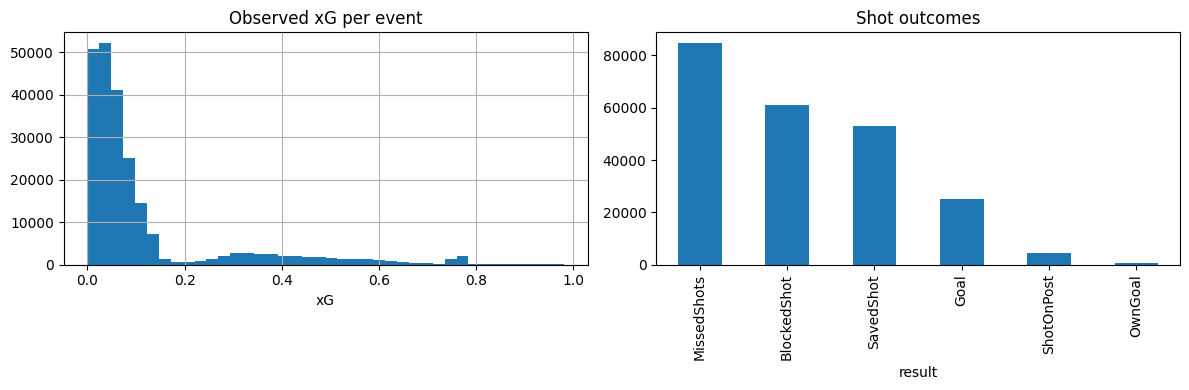

,shots,goals,xg,xg_per_shot
shots,1.000000,0.855363,0.899590,0.166479
goals,0.855363,1.000000,0.933146,0.314518
xg,0.899590,0.933146,1.000000,0.361952
xg_per_shot,0.166479,0.314518,0.361952,1.000000


In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
shots.xG.hist(bins=40,ax=axes[0]);axes[0].set(title='Observed xG per event',xlabel='xG')
shots.result.value_counts().plot.bar(ax=axes[1]);axes[1].set_title('Shot outcomes');plt.tight_layout();plt.show()
players[['shots','goals','xg','xg_per_shot']].corr()

In [6]:
coverage=shots.groupby(['league','season']).match_id.nunique().rename('observed_matches').reset_index()
coverage['expected_matches']=coverage.apply(lambda r:306 if r.league=='Bundesliga' or (r.league=='Ligue 1' and int(r.season[:4])>=2023) else 380,axis=1)
coverage['partial_season']=coverage.season.eq('2025-2026')
coverage

,league,season,observed_matches,expected_matches,partial_season
0,Bundesliga,2020-2021,306,306,False
1,Bundesliga,2021-2022,306,306,False
2,Bundesliga,2022-2023,306,306,False
3,Bundesliga,2023-2024,306,306,False
4,Bundesliga,2024-2025,305,306,False
5,Bundesliga,2025-2026,27,306,True
6,La Liga,2020-2021,380,380,False
7,La Liga,2021-2022,380,380,False
8,La Liga,2022-2023,380,380,False
9,La Liga,2023-2024,380,380,False


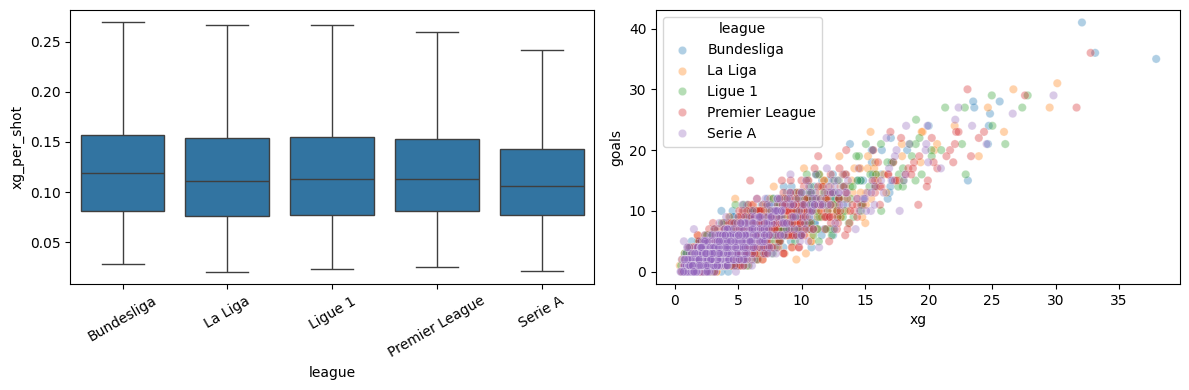

In [7]:
p=players[(~players.partial_season)&players.shots.ge(20)]
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=p,x='league',y='xg_per_shot',showfliers=False,ax=axes[0]);axes[0].tick_params(axis='x',rotation=30)
sns.scatterplot(data=p,x='xg',y='goals',hue='league',alpha=.35,ax=axes[1]);plt.tight_layout();plt.show()

## Interpretation and limitations

Shot quality differs across observed profiles, but xG and goals share shot-volume exposure. The archive covers shooters rather than all rostered players. Expected fixture counts help identify missing coverage; Bundesliga/Serie A 2024/25 have gaps and 2025/26 is partial. No positions or full-match player minutes are supplied by these shot events. Missing positions are not filled through unreviewed FBref joins. These observations support shot exploration, not overall player forecasting or the fitted recommender.